In [1]:
import pandas as pd
import os


In [2]:
DATA_PATH = "../data/raw"

print(os.listdir(DATA_PATH))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [3]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

customers.head()


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
customers.shape

(99441, 5)

In [5]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


In [6]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [7]:
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [8]:
orders.shape

(99441, 8)

In [9]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [10]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [11]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [12]:
customers["customer_id"].nunique()

99441

In [13]:
orders["customer_id"].nunique()

99441

In [14]:
len(orders)

99441

In [15]:
customer_orders = orders.merge(
    customers,
    on="customer_id",
    how="left"
)

In [16]:
customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [17]:
customer_orders.shape

(99441, 12)

In [18]:
customer_orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state'],
      dtype='str')

In [19]:
customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [20]:
customer_orders.shape

(99441, 12)

In [21]:
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [22]:
order_items.shape

(112650, 7)

In [23]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


In [24]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [25]:
order_items["price"].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

In [26]:
orders_items = orders.merge(
    order_items,
    on="order_id",
    how="left"
)

orders_items.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [27]:
orders_items.shape

(113425, 14)

In [28]:
orders_items.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value'],
      dtype='str')

In [29]:
orders_items.shape

(113425, 14)

In [30]:
orders_items["order_id"].value_counts().head(10)

order_id
8272b63d03f5f79c56e9e4120aec44ef    21
1b15974a0141d54e36626dca3fdc731a    20
ab14fdcfbe524636d65ee38360e22ce8    20
428a2f660dc84138d969ccd69a0ab6d5    15
9ef13efd6949e4573a18964dd1bbe7f5    15
73c8ab38f07dc94389065f7eba4f297a    14
9bdc4d4c71aa1de4606060929dee888c    14
37ee401157a3a0b28c9c6d0ed8c3b24b    13
3a213fcdfe7d98be74ea0dc05a8b31ae    12
2c2a19b5703863c908512d135aa6accc    12
Name: count, dtype: int64

In [31]:
orders_items["order_id"].nunique()

99441

In [32]:
orders_items["total_item_value"] = (
    orders_items["price"] + orders_items["freight_value"]
)

orders_items.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,total_item_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,28.62


In [33]:
orders_items[[
    "order_id",
    "price",
    "freight_value",
    "total_item_value"
]].head()

,order_id,price,freight_value,total_item_value
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,28.62


In [34]:
order_summary = orders_items.groupby("order_id").agg(
    total_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_order_value=("total_item_value", "sum")
).reset_index()

order_summary.head()

,order_id,total_items,total_price,total_freight,total_order_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,218.04


In [35]:
order_summary.shape

(99441, 5)

In [36]:
order_summary["order_id"].nunique()

99441

In [37]:
customer_orders_summary = orders.merge(
    order_summary,
    on="order_id",
    how="left"
)

customer_orders_summary.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_items,total_price,total_freight,total_order_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,19.90,8.72,28.62


In [38]:
customer_orders_summary.shape

(99441, 12)

In [39]:
customer_summary = customer_orders_summary.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_items=("total_items", "sum"),
    total_spent=("total_order_value", "sum"),
    average_order_value=("total_order_value", "mean")
).reset_index()

customer_summary.head()

,customer_id,total_orders,total_items,total_spent,average_order_value
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01


In [40]:
customer_summary.shape

(99441, 5)

In [41]:
customer_summary.describe()

,total_orders,total_items,total_spent,average_order_value
count,99441.0,99441.000000,99441.000000,99441.000000
mean,1.0,1.132833,159.326166,159.326166
std,0.0,0.545666,220.058804,220.058804
min,1.0,0.000000,0.000000,0.000000
25%,1.0,1.000000,61.050000,61.050000
50%,1.0,1.000000,104.560000,104.560000
75%,1.0,1.000000,176.000000,176.000000
max,1.0,21.000000,13664.080000,13664.080000


In [42]:
customer_summary.sort_values(
    "total_spent",
    ascending=False
).head(10)

,customer_id,total_orders,total_items,total_spent,average_order_value
8546,1617b1357756262bfa56ab541c47bc16,1,8,13664.08,13664.08
91985,ec5b2ba62e574342386871631fafd3fc,1,4,7274.88,7274.88
77522,c6e2731c5b391845f6800c97401a43a9,1,1,6929.31,6929.31
95124,f48d464a0baaea338cb25f816991ab1f,1,1,6922.21,6922.21
24771,3fd6777bbce08a352fddd04e4a7cc8f6,1,1,6726.66,6726.66
2065,05455dfa7cd02f13d132aa7a6a9729c6,1,6,6081.54,6081.54
86908,df55c14d1476a9a3467f131269c2477f,1,1,4950.34,4950.34
87397,e0a2412720e9ea4f26c1ac985f6a7358,1,2,4809.44,4809.44
14282,24bbf5fd2f2e1b359ee7de94defc4a15,1,1,4764.34,4764.34
23932,3d979689f636322c62418b6346b1c6d2,1,1,4681.78,4681.78


In [43]:
customer_summary.shape

(99441, 5)

In [45]:
customer_orders_summary["order_purchase_timestamp"] = pd.to_datetime(
    customer_orders_summary["order_purchase_timestamp"]
)

customer_orders_summary[
    "order_purchase_timestamp"
].dtype

dtype('<M8[us]')

In [46]:
last_purchase = customer_orders_summary.groupby(
    "customer_id"
)["order_purchase_timestamp"].max().reset_index()

last_purchase.head()

,customer_id,order_purchase_timestamp
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17


In [48]:
reference_date = (
    customer_orders_summary["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

reference_date

Timestamp('2018-10-18 17:30:18')

In [49]:
last_purchase["recency"] = (
    reference_date - last_purchase["order_purchase_timestamp"]
).dt.days

last_purchase.head()

,customer_id,order_purchase_timestamp,recency
0,00012a2ce6f8dcda20d059ce98491703,2017-11-14 16:08:26,338
1,000161a058600d5901f007fab4c27140,2017-07-16 09:40:32,459
2,0001fd6190edaaf884bcaf3d49edf079,2017-02-28 11:06:43,597
3,0002414f95344307404f0ace7a26f1d5,2017-08-16 13:09:20,428
4,000379cdec625522490c315e70c7a9fb,2018-04-02 13:42:17,199


In [50]:
rfm = customer_summary.merge(
    last_purchase[["customer_id", "recency"]],
    on="customer_id",
    how="left"
)

rfm.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,recency
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,338
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,459
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,597
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,428
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,199


In [51]:
rfm.columns

Index(['customer_id', 'total_orders', 'total_items', 'total_spent',
       'average_order_value', 'recency'],
      dtype='str')

In [52]:
rfm[
    ["recency", "total_orders", "total_spent"]
].describe()

,recency,total_orders,total_spent
count,99441.000000,99441.0,99441.000000
mean,290.900192,1.0,159.326166
std,153.667316,0.0,220.058804
min,1.000000,1.0,0.000000
25%,167.000000,1.0,61.050000
50%,272.000000,1.0,104.560000
75%,401.000000,1.0,176.000000
max,773.000000,1.0,13664.080000


In [53]:
rfm["R_score"] = pd.qcut(
    rfm["recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["M_score"] = pd.qcut(
    rfm["total_spent"],
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

rfm.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,recency,R_score,M_score
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,338,2,3
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,459,1,2
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,597,1,4
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,428,2,4
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,199,4,3


In [54]:
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

rfm["RFM_score"] = (
    rfm["R_score"] + rfm["M_score"]
)

rfm.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,recency,R_score,M_score,RFM_score
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,338,2,3,5
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,459,1,2,3
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,597,1,4,5
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,428,2,4,6
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,199,4,3,7


In [55]:
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

rfm["RFM_score"] = (
    rfm["R_score"] + rfm["M_score"]
)

rfm.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,recency,R_score,M_score,RFM_score
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,338,2,3,5
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,459,1,2,3
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,597,1,4,5
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,428,2,4,6
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,199,4,3,7


In [56]:
rfm["segment"] = "Regular"

rfm.loc[
    (rfm["R_score"] >= 4) & (rfm["M_score"] >= 4),
    "segment"
] = "High Value - Recent"

rfm.loc[
    (rfm["R_score"] >= 4) & (rfm["M_score"] <= 2),
    "segment"
] = "Recent - Low Value"

rfm.loc[
    (rfm["R_score"] <= 2) & (rfm["M_score"] >= 4),
    "segment"
] = "High Value - Inactive"

rfm.loc[
    (rfm["R_score"] <= 2) & (rfm["M_score"] <= 2),
    "segment"
] = "Low Value - Inactive"

rfm["segment"].value_counts()

segment
Regular                  35785
High Value - Recent      16490
Low Value - Inactive     16463
High Value - Inactive    15389
Recent - Low Value       15314
Name: count, dtype: int64

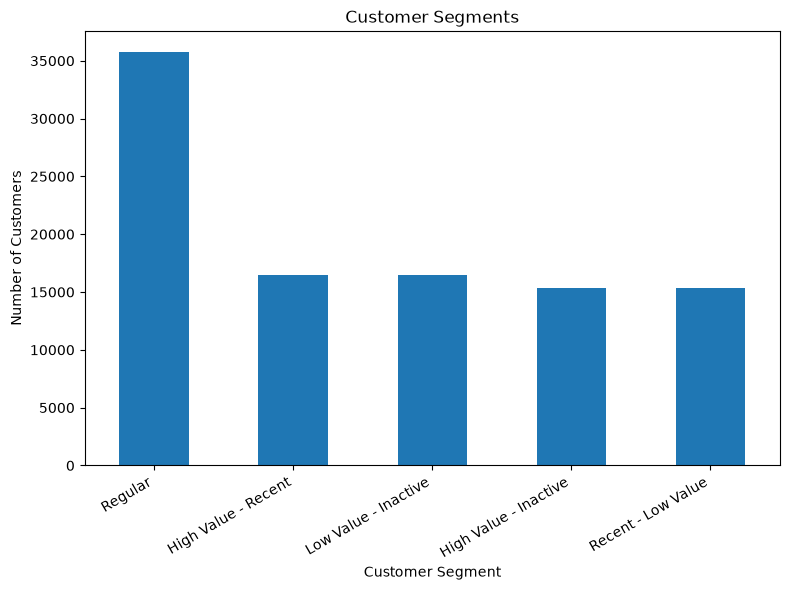

In [58]:
import matplotlib.pyplot as plt

segment_counts = rfm["segment"].value_counts()

plt.figure(figsize=(8, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [59]:
segment_spending = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    total_revenue=("total_spent", "sum"),
    average_spending=("total_spent", "mean")
).reset_index()

segment_spending.sort_values(
    "total_revenue",
    ascending=False
)

,segment,customers,total_revenue,average_spending
1,High Value - Recent,16490,4867311.66,295.167475
4,Regular,35785,4664672.81,130.352740
0,High Value - Inactive,15389,4632553.10,301.030158
2,Low Value - Inactive,16463,867677.82,52.704721
3,Recent - Low Value,15314,811337.85,52.980139


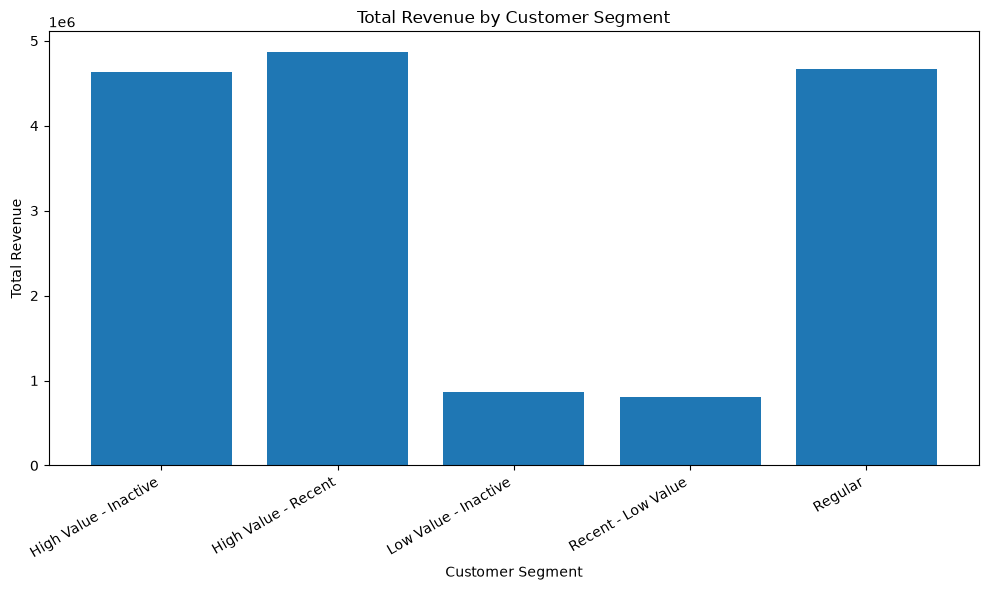

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    segment_spending["segment"],
    segment_spending["total_revenue"]
)

plt.title("Total Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

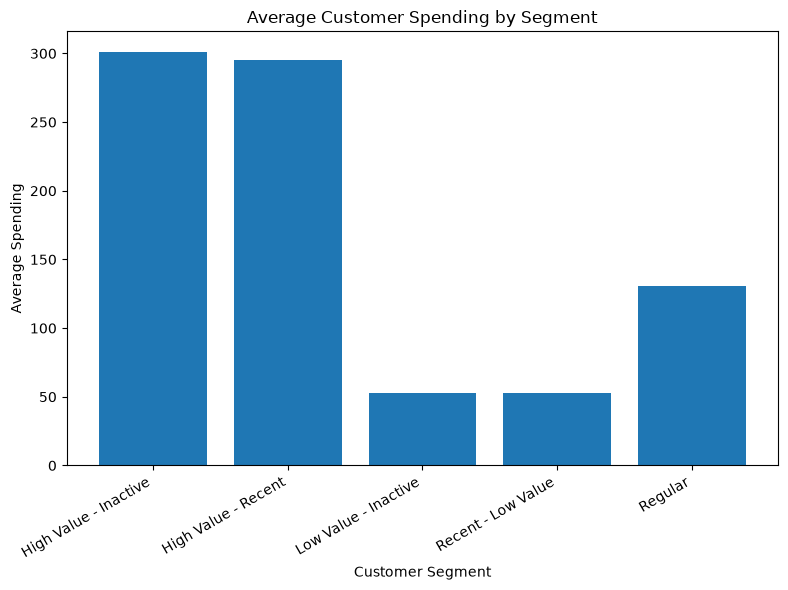

In [62]:
plt.figure(figsize=(8, 6))

plt.bar(
    segment_spending["segment"],
    segment_spending["average_spending"]
)

plt.title("Average Customer Spending by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

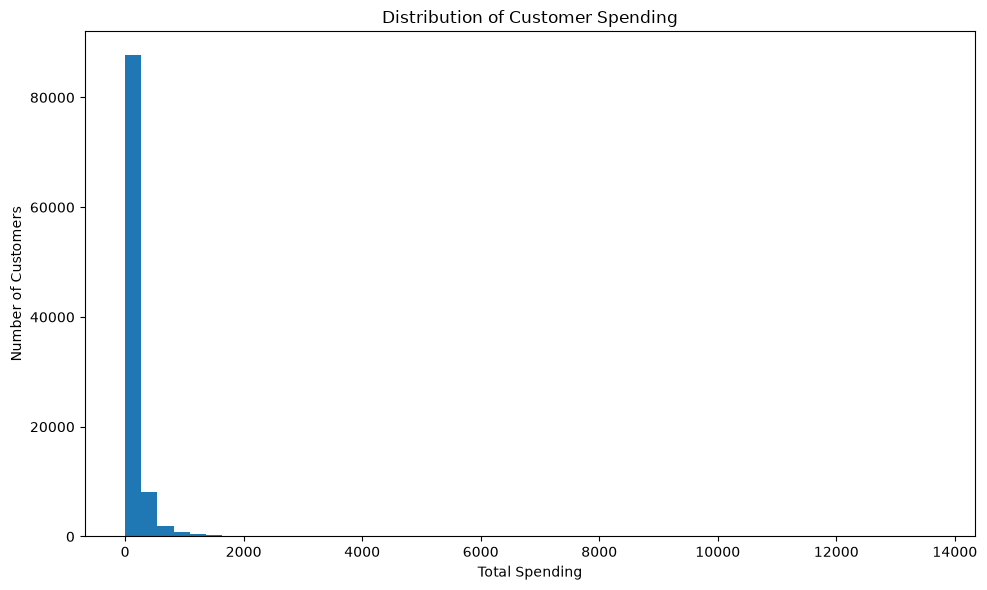

In [65]:
plt.figure(figsize=(10, 6))

plt.hist(
    rfm["total_spent"],
    bins=50
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [66]:
reviews = pd.read_csv(
    "../data/raw/olist_order_reviews_dataset.csv"
)

reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [67]:
reviews["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

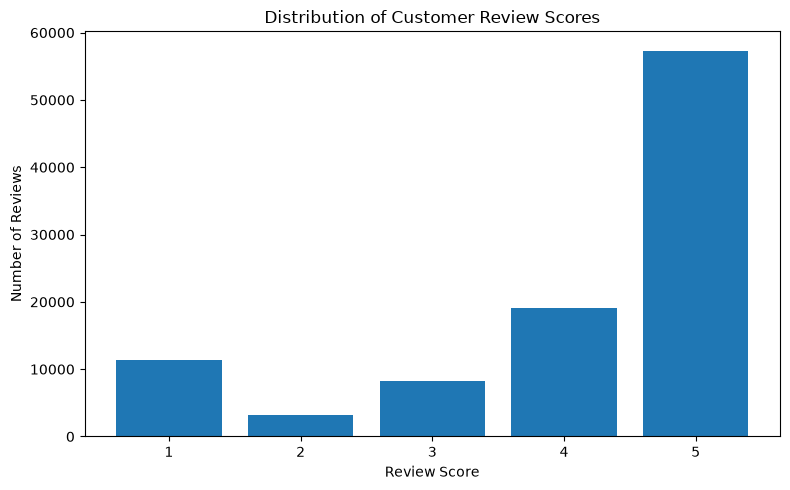

In [68]:
review_counts = reviews["review_score"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    review_counts.index,
    review_counts.values
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()
plt.show()

In [69]:
customer_reviews = customer_orders_summary.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="left"
)

customer_reviews.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_items,total_price,total_freight,total_order_value,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,29.99,8.72,38.71,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,118.70,22.76,141.46,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,159.90,19.22,179.12,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,45.00,27.20,72.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,19.90,8.72,28.62,5.0


In [70]:
customer_reviews["order_id"].duplicated().sum()

np.int64(551)

In [71]:
review_per_order = reviews.groupby("order_id").size()

review_per_order.value_counts().sort_index()

1    98126
2      543
3        4
Name: count, dtype: int64

In [72]:
order_reviews = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean")
).reset_index()

order_reviews.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [73]:
order_reviews["order_id"].duplicated().sum()

np.int64(0)

In [74]:
customer_reviews = customer_orders_summary.merge(
    order_reviews,
    on="order_id",
    how="left"
)

customer_reviews.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_items,total_price,total_freight,total_order_value,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,29.99,8.72,38.71,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,118.70,22.76,141.46,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,159.90,19.22,179.12,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,45.00,27.20,72.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,19.90,8.72,28.62,5.0


In [75]:
customer_reviews["order_id"].duplicated().sum()

np.int64(0)

In [76]:

customer_reviews["review_score"].value_counts().sort_index()

review_score
1.000000    11316
1.500000        8
2.000000     3125
2.500000       34
3.000000     8136
3.333333        1
3.500000       25
4.000000    19018
4.333333        1
4.500000       54
5.000000    56955
Name: count, dtype: int64

In [77]:
review_spending = customer_reviews.groupby("review_score").agg(
    orders=("order_id", "nunique"),
    average_order_value=("total_order_value", "mean"),
    total_revenue=("total_order_value", "sum")
).reset_index()

review_spending

,review_score,orders,average_order_value,total_revenue
0,1.000000,11316,185.464685,2098718.37
1,1.500000,8,204.702500,1637.62
2,2.000000,3125,168.451158,526409.87
3,2.500000,34,129.309118,4396.51
4,3.000000,8136,150.217166,1222166.86
5,3.333333,1,42.110000,42.11
6,3.500000,25,143.645600,3591.14
7,4.000000,19018,154.596125,2940109.10
8,4.333333,1,42.770000,42.77
9,4.500000,54,121.889815,6582.05


In [78]:
customer_reviews["order_purchase_timestamp"] = pd.to_datetime(
    customer_reviews["order_purchase_timestamp"]
)

customer_reviews["order_delivered_customer_date"] = pd.to_datetime(
    customer_reviews["order_delivered_customer_date"]
)

customer_reviews["order_estimated_delivery_date"] = pd.to_datetime(
    customer_reviews["order_estimated_delivery_date"]
)

customer_reviews["delivery_days"] = (
    customer_reviews["order_delivered_customer_date"]
    - customer_reviews["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

customer_reviews["delivery_delay_days"] = (
    customer_reviews["order_delivered_customer_date"]
    - customer_reviews["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

customer_reviews[
    [
        "order_id",
        "review_score",
        "delivery_days",
        "delivery_delay_days"
    ]
].head()

,order_id,review_score,delivery_days,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,4.0,8.436574,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,4.0,13.782037,-5.355729
2,47770eb9100c2d0c44946d9cf07ec65d,5.0,9.394213,-17.245498
3,949d5b44dbf5de918fe9c16f97b45f8a,5.0,13.208750,-12.980069
4,ad21c59c0840e6cb83a9ceb5573f8159,5.0,2.873877,-9.238171


In [79]:
customer_reviews[
    ["delivery_days", "delivery_delay_days"]
].describe()

,delivery_days,delivery_delay_days
count,96476.000000,96476.000000
mean,12.558702,-11.179120
std,9.546530,10.186113
min,0.533414,-146.016123
25%,6.766403,-16.244384
50%,10.217755,-11.948941
75%,15.720327,-6.390000
max,209.628611,188.975081


In [80]:
customer_reviews[
    ["delivery_days", "delivery_delay_days"]
].isnull().sum()

delivery_days          2965
delivery_delay_days    2965
dtype: int64

In [81]:
customer_reviews["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [82]:
delivery_reviews = customer_reviews[
    customer_reviews["delivery_days"].notna()
].groupby("review_score").agg(
    average_delivery_days=("delivery_days", "mean"),
    average_delay_days=("delivery_delay_days", "mean"),
    orders=("order_id", "nunique")
).reset_index()

delivery_reviews

,review_score,average_delivery_days,average_delay_days,orders
0,1.000000,21.339995,-3.336156,9316
1,1.500000,17.528027,-5.342746,8
2,2.000000,16.663602,-7.938540,2916
3,2.500000,18.670304,-6.819354,30
4,3.000000,14.246112,-10.084415,7916
5,3.333333,22.033148,-13.091065,1
6,3.500000,13.282356,-13.220016,23
7,4.000000,12.306680,-11.682696,18868
8,4.333333,3.765359,-10.287153,1
9,4.500000,12.803099,-12.358327,53


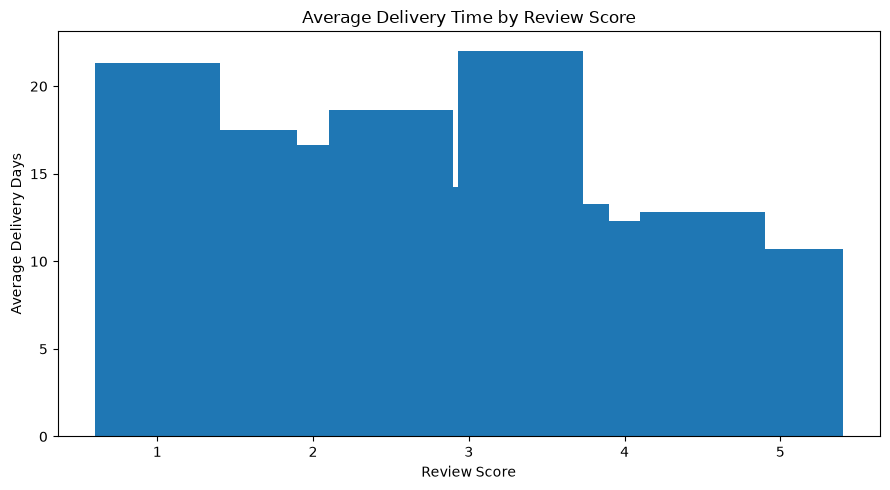

In [83]:
plt.figure(figsize=(9, 5))

plt.bar(
    delivery_reviews["review_score"],
    delivery_reviews["average_delivery_days"]
)

plt.title("Average Delivery Time by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Average Delivery Days")

plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()
plt.show()

In [84]:
products = pd.read_csv(
    "../data/raw/olist_products_dataset.csv"
)

products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [85]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [86]:

category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [87]:
category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [88]:
category_translation.columns

Index(['product_category_name', 'product_category_name_english'], dtype='str')

In [89]:
category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [90]:
category_translation.columns

Index(['product_category_name', 'product_category_name_english'], dtype='str')

In [91]:
products_with_category = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

products_with_category.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


In [92]:
products_with_category["product_category_name_english"].isnull().sum()

np.int64(623)

In [93]:
products_with_category[
    [
        "product_category_name",
        "product_category_name_english"
    ]
].isnull().sum()

product_category_name            610
product_category_name_english    623
dtype: int64

In [94]:
products_with_category[
    "product_category_name_english"
].value_counts(dropna=False).head(15)

product_category_name_english
bed_bath_table              3029
sports_leisure              2867
furniture_decor             2657
health_beauty               2444
housewares                  2335
auto                        1900
computers_accessories       1639
toys                        1411
watches_gifts               1329
telephony                   1134
baby                         919
perfumery                    868
stationery                   849
fashion_bags_accessories     849
cool_stuff                   789
Name: count, dtype: int64

In [95]:

items_with_category = order_items.merge(
    products_with_category[
        [
            "product_id",
            "product_category_name_english"
        ]
    ],
    on="product_id",
    how="left"
)

items_with_category.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,garden_tools


In [96]:
category_revenue = items_with_category.groupby(
    "product_category_name_english"
).agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count")
).reset_index()

category_revenue = category_revenue.sort_values(
    "total_revenue",
    ascending=False
)

category_revenue.head(15)

,product_category_name_english,total_revenue,total_orders,total_items
43,health_beauty,1258681.34,8836,9670
70,watches_gifts,1205005.68,5624,5991
7,bed_bath_table,1036988.68,9417,11115
65,sports_leisure,988048.97,7720,8641
15,computers_accessories,911954.32,6689,7827
39,furniture_decor,729762.49,6449,8334
20,cool_stuff,635290.85,3632,3796
49,housewares,632248.66,5884,6964
5,auto,592720.11,3897,4235
42,garden_tools,485256.46,3518,4347


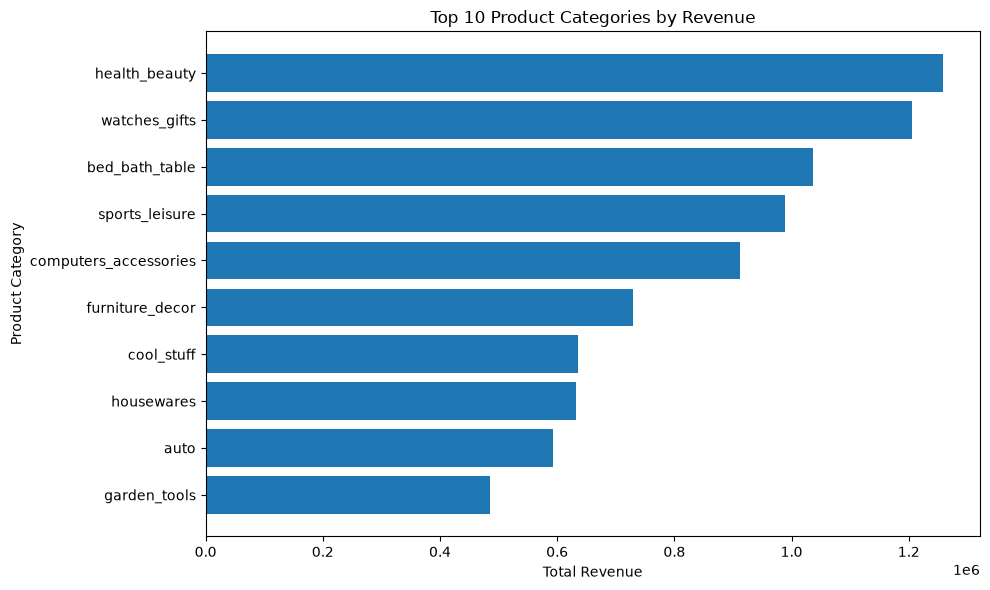

In [97]:
top_categories = category_revenue.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["product_category_name_english"][::-1],
    top_categories["total_revenue"][::-1]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [98]:
category_revenue.head(10)

,product_category_name_english,total_revenue,total_orders,total_items
43,health_beauty,1258681.34,8836,9670
70,watches_gifts,1205005.68,5624,5991
7,bed_bath_table,1036988.68,9417,11115
65,sports_leisure,988048.97,7720,8641
15,computers_accessories,911954.32,6689,7827
39,furniture_decor,729762.49,6449,8334
20,cool_stuff,635290.85,3632,3796
49,housewares,632248.66,5884,6964
5,auto,592720.11,3897,4235
42,garden_tools,485256.46,3518,4347


In [99]:
seller_performance = order_items.groupby("seller_id").agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count"),
    average_item_price=("price", "mean")
).reset_index()

seller_performance = seller_performance.sort_values(
    "total_revenue",
    ascending=False
)

seller_performance.head(10)

,seller_id,total_revenue,total_orders,total_items,average_item_price
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1132,1156,198.505735
1013,53243585a1d6dc2643021fd1853d8905,222776.05,358,410,543.356220
881,4a3ca9315b744ce9f8e9374361493884,200472.92,1806,1987,100.892260
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,585,586,331.129744
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,982,1364,137.774113
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,336,340,518.917265
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1314,1551,103.311779
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1160,1171,121.046567
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,915,1428,97.316912
1824,955fee9216a65b617aa5c0531780ce60,135171.70,1287,1499,90.174583


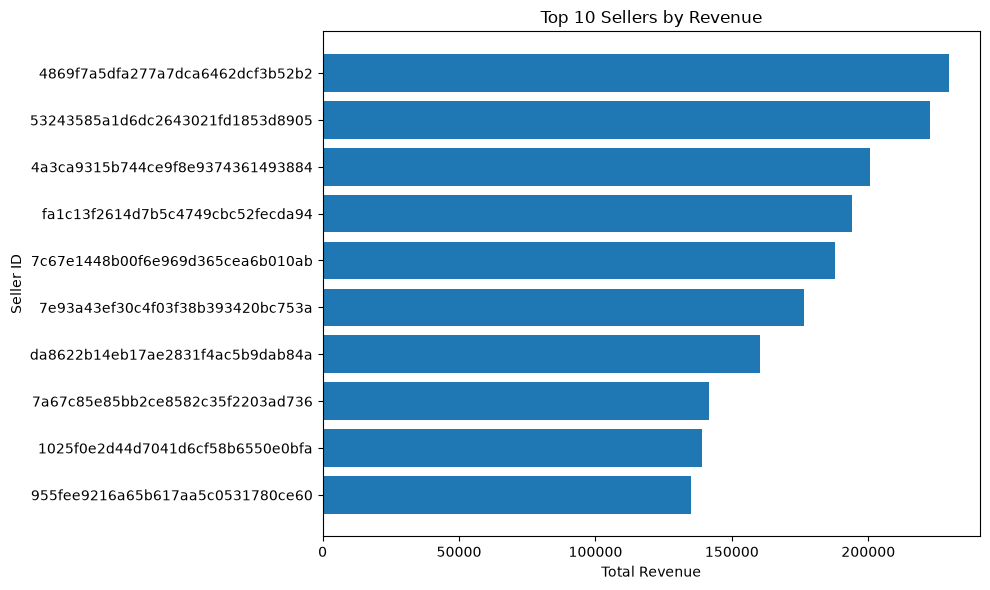

In [100]:
top_sellers = seller_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_sellers["seller_id"].astype(str)[::-1],
    top_sellers["total_revenue"][::-1]
)

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Seller ID")

plt.tight_layout()
plt.show()

In [101]:
customer_reviews["order_purchase_timestamp"] = pd.to_datetime(
    customer_reviews["order_purchase_timestamp"]
)

customer_reviews["purchase_month"] = (
    customer_reviews["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_revenue = customer_reviews.groupby(
    "purchase_month"
).agg(
    total_revenue=("total_order_value", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

monthly_revenue.head()

,purchase_month,total_revenue,total_orders
0,2016-09,354.75,4
1,2016-10,56808.84,324
2,2016-12,19.62,1
3,2017-01,137188.49,800
4,2017-02,286280.62,1780


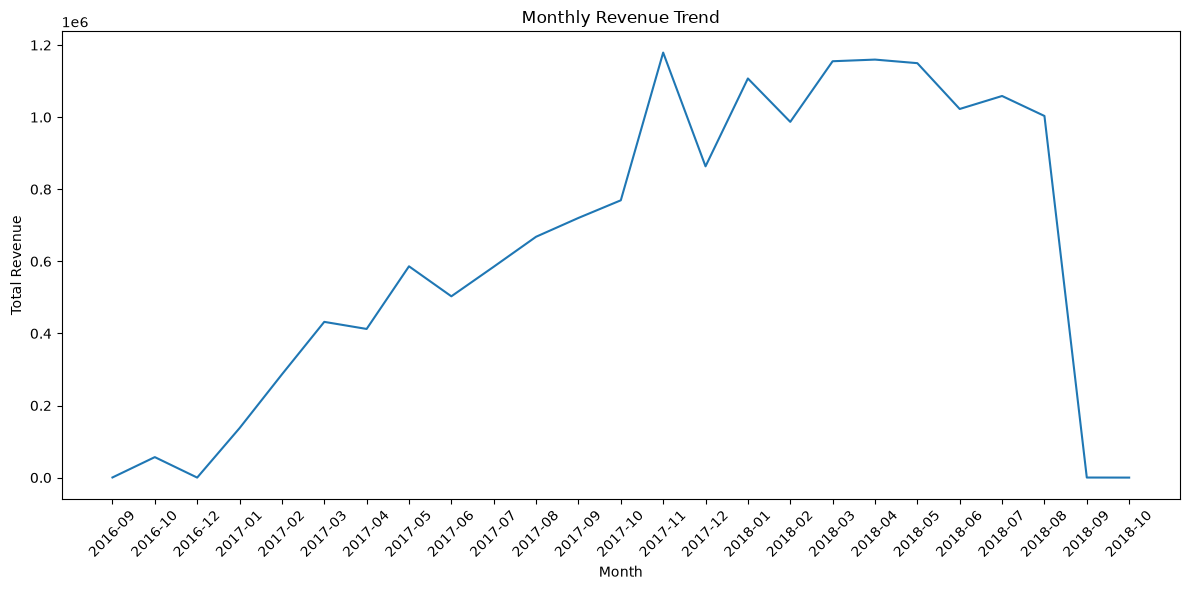

In [102]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["purchase_month"],
    monthly_revenue["total_revenue"]
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [103]:
customer_features = customer_reviews.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_items=("total_items", "sum"),
    total_spent=("total_order_value", "sum"),
    average_order_value=("total_order_value", "mean"),
    average_review_score=("review_score", "mean"),
    average_delivery_days=("delivery_days", "mean"),
    average_delivery_delay=("delivery_delay_days", "mean")
).reset_index()

customer_features.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,1.0,13.981296,-5.346181
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,4.0,9.386817,-9.210035
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,5.0,5.910486,-15.626516
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,5.0,28.289375,-0.162477
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,4.0,11.276979,-4.151991


In [104]:
customer_features.shape

(99441, 8)

In [105]:
customer_features = customer_features.merge(
    last_purchase[["customer_id", "recency"]],
    on="customer_id",
    how="left"
)

customer_features.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay,recency
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,1.0,13.981296,-5.346181,338
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,4.0,9.386817,-9.210035,459
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,5.0,5.910486,-15.626516,597
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,5.0,28.289375,-0.162477,428
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,4.0,11.276979,-4.151991,199


In [106]:
customer_features.columns

Index(['customer_id', 'total_orders', 'total_items', 'total_spent',
       'average_order_value', 'average_review_score', 'average_delivery_days',
       'average_delivery_delay', 'recency'],
      dtype='str')

In [107]:
customer_features.isnull().sum()

customer_id                  0
total_orders                 0
total_items                  0
total_spent                  0
average_order_value          0
average_review_score       768
average_delivery_days     2965
average_delivery_delay    2965
recency                      0
dtype: int64

In [108]:

customer_features["has_review"] = (
    customer_features["average_review_score"].notna().astype(int)
)

customer_features["has_delivery"] = (
    customer_features["average_delivery_days"].notna().astype(int)
)

customer_features.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay,recency,has_review,has_delivery
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,1.0,13.981296,-5.346181,338,1,1
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,4.0,9.386817,-9.210035,459,1,1
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,5.0,5.910486,-15.626516,597,1,1
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,5.0,28.289375,-0.162477,428,1,1
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,4.0,11.276979,-4.151991,199,1,1


In [109]:
customer_features["average_review_score"] = (
    customer_features["average_review_score"]
    .fillna(customer_features["average_review_score"].median())
)

customer_features["average_delivery_days"] = (
    customer_features["average_delivery_days"]
    .fillna(customer_features["average_delivery_days"].median())
)

customer_features["average_delivery_delay"] = (
    customer_features["average_delivery_delay"]
    .fillna(customer_features["average_delivery_delay"].median())
)

In [110]:
customer_features.isnull().sum()

customer_id               0
total_orders              0
total_items               0
total_spent               0
average_order_value       0
average_review_score      0
average_delivery_days     0
average_delivery_delay    0
recency                   0
has_review                0
has_delivery              0
dtype: int64

In [111]:
customer_location = customers[
    [
        "customer_id",
        "customer_city",
        "customer_state"
    ]
].drop_duplicates("customer_id")

customer_features = customer_features.merge(
    customer_location,
    on="customer_id",
    how="left"
)

customer_features.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay,recency,has_review,has_delivery,customer_city,customer_state
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,1.0,13.981296,-5.346181,338,1,1,osasco,SP
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,4.0,9.386817,-9.210035,459,1,1,itapecerica,MG
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,5.0,5.910486,-15.626516,597,1,1,nova venecia,ES
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,5.0,28.289375,-0.162477,428,1,1,mendonca,MG
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,4.0,11.276979,-4.151991,199,1,1,sao paulo,SP


In [112]:
customer_features.shape

(99441, 13)

In [113]:
customer_features[
    ["customer_city", "customer_state"]
].isnull().sum()

customer_city     0
customer_state    0
dtype: int64

In [114]:
customer_features.head()

,customer_id,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay,recency,has_review,has_delivery,customer_city,customer_state
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,1.0,13.981296,-5.346181,338,1,1,osasco,SP
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,4.0,9.386817,-9.210035,459,1,1,itapecerica,MG
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,5.0,5.910486,-15.626516,597,1,1,nova venecia,ES
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,5.0,28.289375,-0.162477,428,1,1,mendonca,MG
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,4.0,11.276979,-4.151991,199,1,1,sao paulo,SP


In [115]:
customer_features.shape

(99441, 13)

In [116]:
customer_features.columns

Index(['customer_id', 'total_orders', 'total_items', 'total_spent',
       'average_order_value', 'average_review_score', 'average_delivery_days',
       'average_delivery_delay', 'recency', 'has_review', 'has_delivery',
       'customer_city', 'customer_state'],
      dtype='str')

In [117]:
ml_features = customer_features.drop(
    columns=[
        "customer_id",
        "customer_city",
        "customer_state"
    ]
)

ml_features.head()

,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay,recency,has_review,has_delivery
0,1,1,114.74,114.74,1.0,13.981296,-5.346181,338,1,1
1,1,1,67.41,67.41,4.0,9.386817,-9.210035,459,1,1
2,1,1,195.42,195.42,5.0,5.910486,-15.626516,597,1,1
3,1,1,179.35,179.35,5.0,28.289375,-0.162477,428,1,1
4,1,1,107.01,107.01,4.0,11.276979,-4.151991,199,1,1


In [118]:
ml_features.shape

(99441, 10)

In [119]:
recency_threshold = rfm["recency"].quantile(0.75)

recency_threshold

np.float64(401.0)

In [120]:
customer_features["retention_risk"] = (
    customer_features["recency"] >= recency_threshold
).astype(int)

customer_features["retention_risk"].value_counts()

retention_risk
0    74545
1    24896
Name: count, dtype: int64

In [121]:
X = customer_features.drop(
    columns=[
        "customer_id",
        "customer_city",
        "customer_state",
        "recency",
        "retention_risk"
    ]
)

y = customer_features["retention_risk"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (99441, 9)
y shape: (99441,)


In [122]:
y.value_counts(normalize=True)

retention_risk
0    0.74964
1    0.25036
Name: proportion, dtype: float64

In [123]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (79552, 9)
Testing data: (19889, 9)


In [124]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [125]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print(y_pred[:10])
print(y_prob[:10])

[0 0 0 0 0 0 0 0 0 0]
[0.207295   0.21897958 0.3003311  0.38369083 0.24187591 0.22975191
 0.45124734 0.20801843 0.20908558 0.28367106]


In [126]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.7499622907134597
Precision: 0.5333333333333333
Recall   : 0.009640490058244628
F1 Score : 0.018938646675872955
ROC-AUC  : 0.5916766448594493

Classification Report:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86     14910
           1       0.53      0.01      0.02      4979

    accuracy                           0.75     19889
   macro avg       0.64      0.50      0.44     19889
weighted avg       0.70      0.75      0.65     19889



In [127]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [128]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print(rf_pred[:10])
print(rf_prob[:10])

[0 0 1 0 1 1 1 1 0 0]
[0.31  0.14  0.755 0.16  0.595 0.58  0.615 0.715 0.175 0.395]


In [129]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Accuracy : 0.7323143446125999
Precision: 0.4619625137816979
Recall   : 0.420767222333802
F1 Score : 0.4404036157241959
ROC-AUC  : 0.706772609951737


In [130]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance

,feature,importance
6,average_delivery_delay,0.298277
5,average_delivery_days,0.244575
2,total_spent,0.200502
3,average_order_value,0.200320
4,average_review_score,0.036602
1,total_items,0.016248
7,has_review,0.002134
8,has_delivery,0.001341
0,total_orders,0.000000


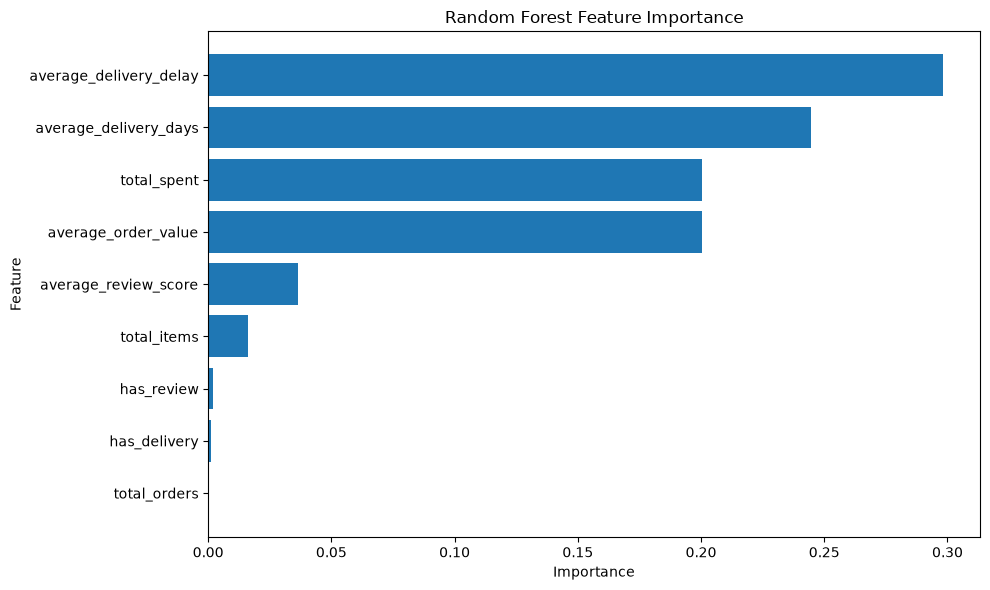

In [131]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"][::-1],
    feature_importance["importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [132]:
import shap

explainer = shap.TreeExplainer(rf_model)

X_sample = X_test.sample(
    1000,
    random_state=42
)

shap_values = explainer.shap_values(X_sample)

print("SHAP analysis completed.")

SHAP analysis completed.


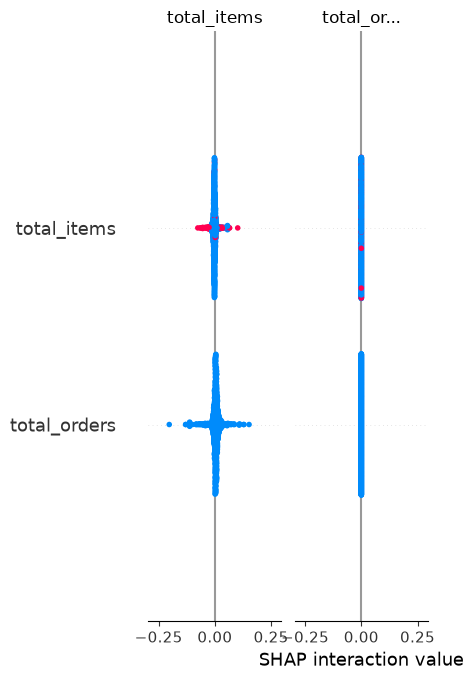

In [133]:
shap.summary_plot(
    shap_values,
    X_sample
)

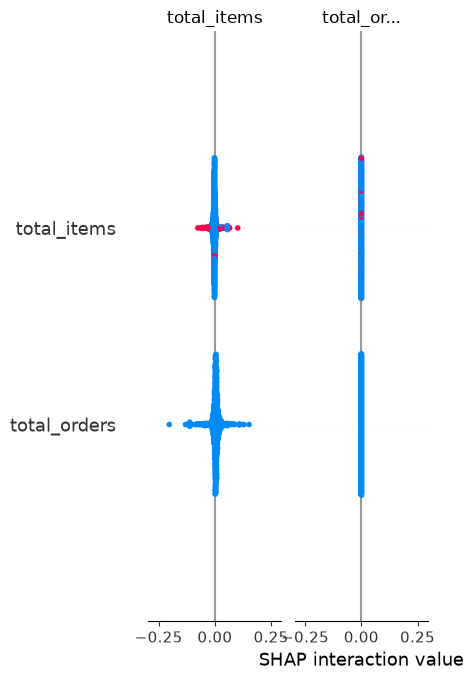

In [134]:
shap.summary_plot(
    shap_values,
    X_sample,
    plot_type="bar"
)

In [137]:
import numpy as np

print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(1000, 9, 2)


In [138]:
shap_values_positive = shap_values[:, :, 1]

shap_importance = pd.DataFrame({
    "feature": X_sample.columns,
    "importance": np.abs(shap_values_positive).mean(axis=0)
}).sort_values(
    "importance",
    ascending=False
)

shap_importance

,feature,importance
6,average_delivery_delay,0.089663
5,average_delivery_days,0.053941
3,average_order_value,0.038901
2,total_spent,0.037644
4,average_review_score,0.015623
1,total_items,0.006034
8,has_delivery,0.005021
7,has_review,0.000693
0,total_orders,0.000000


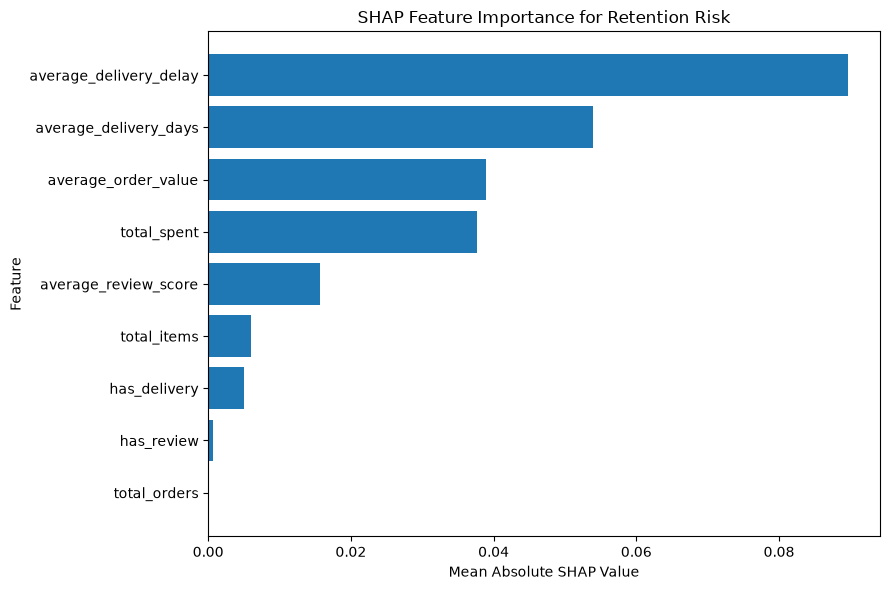

In [139]:
plt.figure(figsize=(9, 6))

plt.barh(
    shap_importance["feature"][::-1],
    shap_importance["importance"][::-1]
)

plt.title("SHAP Feature Importance for Retention Risk")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [155]:
# ============================================
# Save SHAP Feature Importance
# ============================================

import os

# Make sure processed-data folder exists
os.makedirs("../data/processed", exist_ok=True)

# Path for SHAP results
shap_path = "../data/processed/shap_importance.csv"

# Save SHAP feature importance
shap_importance.to_csv(
    shap_path,
    index=False
)

print("SHAP feature importance saved successfully!")
print("File path:", shap_path)
print("Features:", shap_importance.shape[0])

SHAP feature importance saved successfully!
File path: ../data/processed/shap_importance.csv
Features: 9


Created the SQL database

In [140]:
import sqlite3

# Create SQLite database
conn = sqlite3.connect("../data/processed/olist_customer_intelligence.db")

print("Database connected successfully!")

Database connected successfully!


In [141]:
customer_features.to_sql(
    "customer_features",
    conn,
    if_exists="replace",
    index=False
)

print("customer_features table created successfully!")

customer_features table created successfully!


In [142]:
query = """
SELECT *
FROM customer_features
LIMIT 5;
"""

sql_result = pd.read_sql_query(query, conn)

sql_result

,customer_id,total_orders,total_items,total_spent,average_order_value,average_review_score,average_delivery_days,average_delivery_delay,recency,has_review,has_delivery,customer_city,customer_state,retention_risk
0,00012a2ce6f8dcda20d059ce98491703,1,1,114.74,114.74,1.0,13.981296,-5.346181,338,1,1,osasco,SP,0
1,000161a058600d5901f007fab4c27140,1,1,67.41,67.41,4.0,9.386817,-9.210035,459,1,1,itapecerica,MG,1
2,0001fd6190edaaf884bcaf3d49edf079,1,1,195.42,195.42,5.0,5.910486,-15.626516,597,1,1,nova venecia,ES,1
3,0002414f95344307404f0ace7a26f1d5,1,1,179.35,179.35,5.0,28.289375,-0.162477,428,1,1,mendonca,MG,1
4,000379cdec625522490c315e70c7a9fb,1,1,107.01,107.01,4.0,11.276979,-4.151991,199,1,1,sao paulo,SP,0


In [143]:
query = """
SELECT
    customer_id,
    total_spent,
    average_order_value,
    average_review_score
FROM customer_features
WHERE total_spent > 500
ORDER BY total_spent DESC;
"""

high_value_customers = pd.read_sql_query(
    query,
    conn
)

high_value_customers.head(10)

,customer_id,total_spent,average_order_value,average_review_score
0,1617b1357756262bfa56ab541c47bc16,13664.08,13664.08,1.0
1,ec5b2ba62e574342386871631fafd3fc,7274.88,7274.88,1.0
2,c6e2731c5b391845f6800c97401a43a9,6929.31,6929.31,5.0
3,f48d464a0baaea338cb25f816991ab1f,6922.21,6922.21,5.0
4,3fd6777bbce08a352fddd04e4a7cc8f6,6726.66,6726.66,5.0
5,05455dfa7cd02f13d132aa7a6a9729c6,6081.54,6081.54,1.0
6,df55c14d1476a9a3467f131269c2477f,4950.34,4950.34,5.0
7,e0a2412720e9ea4f26c1ac985f6a7358,4809.44,4809.44,1.0
8,24bbf5fd2f2e1b359ee7de94defc4a15,4764.34,4764.34,4.0
9,3d979689f636322c62418b6346b1c6d2,4681.78,4681.78,5.0


In [144]:
query = """
SELECT
    retention_risk,
    COUNT(*) AS customer_count,
    SUM(total_spent) AS total_revenue,
    AVG(total_spent) AS average_spending
FROM customer_features
GROUP BY retention_risk
ORDER BY retention_risk;
"""

risk_summary = pd.read_sql_query(
    query,
    conn
)

risk_summary

,retention_risk,customer_count,total_revenue,average_spending
0,0,74545,11889639.81,159.496141
1,1,24896,3953913.43,158.817217


In [145]:
query = """
SELECT
    average_review_score,
    COUNT(*) AS customer_count,
    AVG(total_spent) AS average_spending,
    AVG(average_delivery_days) AS average_delivery_days
FROM customer_features
GROUP BY average_review_score
ORDER BY average_review_score;
"""

review_sql = pd.read_sql_query(query, conn)

review_sql

,average_review_score,customer_count,average_spending,average_delivery_days
0,1.000000,11316,185.464685,19.374240
1,1.500000,8,204.702500,17.528027
2,2.000000,3125,168.451158,16.232503
3,2.500000,34,129.309118,17.675886
4,3.000000,8136,150.217166,14.137184
5,3.333333,1,42.110000,22.033148
6,3.500000,25,143.645600,13.037188
7,4.000000,19018,154.596125,12.290204
8,4.333333,1,42.770000,3.765359
9,4.500000,54,121.889815,12.755222


In [146]:
query = """
SELECT
    CASE
        WHEN total_spent >= 300 THEN 'High Value'
        WHEN total_spent >= 150 THEN 'Medium Value'
        ELSE 'Low Value'
    END AS customer_value_segment,
    COUNT(*) AS customer_count,
    SUM(total_spent) AS total_revenue,
    AVG(total_spent) AS average_spending
FROM customer_features
GROUP BY customer_value_segment
ORDER BY total_revenue DESC;
"""

value_segments = pd.read_sql_query(query, conn)

value_segments

,customer_value_segment,customer_count,total_revenue,average_spending
0,High Value,10212,6154569.90,602.680170
1,Low Value,67344,5249238.21,77.946635
2,Medium Value,21885,4439745.13,202.867038


In [ ]:
# ============================================
# Compare Machine Learning Models
# ============================================

# Import evaluation metrics
# These metrics help us understand how well each model performs
from sklearn.metrics import (
    accuracy_score,      # Overall percentage of correct predictions
    precision_score,     # How many predicted risk customers were actually risky
    recall_score,        # How many actual risk customers the model detected
    f1_score,           # Balance between precision and recall
    roc_auc_score        # Measures how well the model separates the two classes
)


# Create a table to compare our two models
# We already trained:
# 1. Logistic Regression
# 2. Random Forest

model_comparison = pd.DataFrame({

    # Names of the models
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    # Accuracy:
    # Percentage of all predictions that were correct
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],

    # Precision:
    # Of the customers predicted as high-risk,
    # how many were actually high-risk?
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],

    # Recall:
    # Of all the actual high-risk customers,
    # how many did the model successfully identify?
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],

    # F1 Score:
    # Combines precision and recall into one metric
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],

    # ROC-AUC:
    # Measures how well the model separates
    # lower-risk and higher-risk customers
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})


# Display the comparison table
model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.749962,0.533333,0.009640,0.018939,0.591677
1,Random Forest,0.732314,0.461963,0.420767,0.440404,0.706773


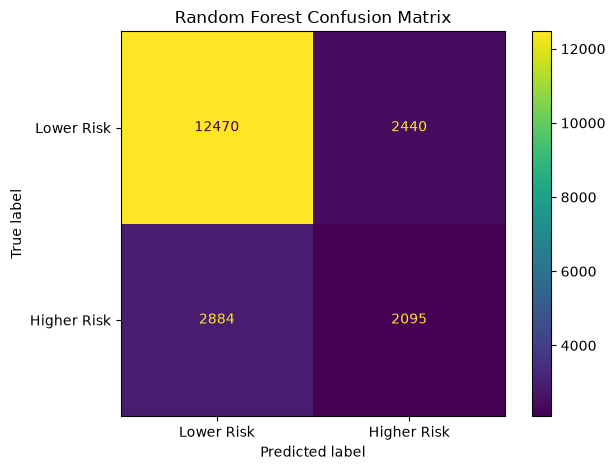

In [150]:
# ============================================
# Confusion Matrix for Random Forest
# ============================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compare the actual risk labels with
# the Random Forest predictions
cm = confusion_matrix(y_test, rf_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lower Risk", "Higher Risk"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

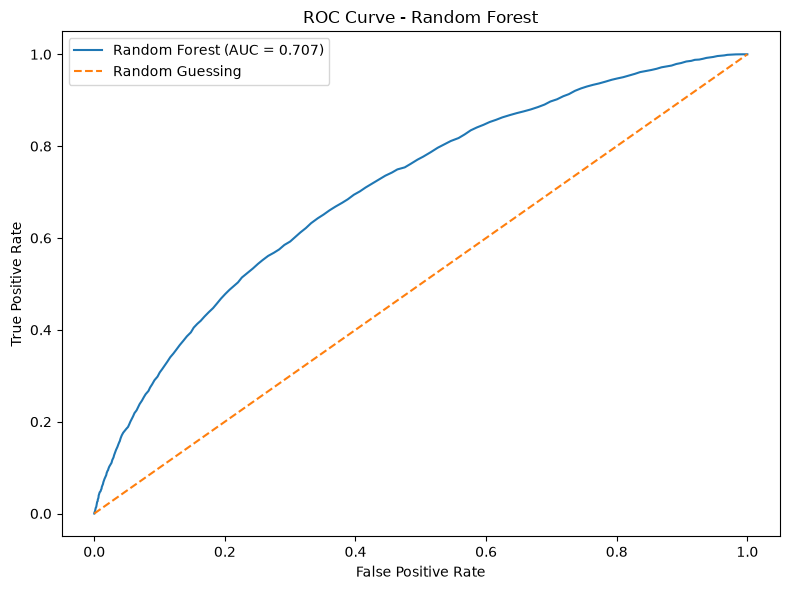

In [ ]:
# ============================================
# ROC Curve for Random Forest
# ============================================

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(
    y_test,
    rf_prob
)

# Calculate ROC-AUC score
roc_auc = roc_auc_score(
    y_test,
    rf_prob
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

# Random guessing reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guessing"
)

plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()

In [152]:
# ============================================
# Save the Random Forest Model
# ============================================

import joblib
import os

# Make sure the models folder exists
os.makedirs("../models", exist_ok=True)

# Save the trained Random Forest model
model_path = "../models/retention_risk_model.joblib"

joblib.dump(
    rf_model,
    model_path
)

print("Random Forest model saved successfully!")
print("Model path:", model_path)

Random Forest model saved successfully!
Model path: ../models/retention_risk_model.joblib


In [153]:
# ============================================
# Test the Saved Model
# ============================================

import joblib

# Load the saved Random Forest model
loaded_model = joblib.load(
    "../models/retention_risk_model.joblib"
)

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Check whether the loaded model gives
# the same predictions as the original model
print(
    "Predictions match:",
    (loaded_predictions == rf_pred).all()
)

Predictions match: True


In [154]:
# ============================================
# Save Processed Customer Features
# ============================================

import os

# Make sure the processed-data folder exists
os.makedirs("../data/processed", exist_ok=True)

# Path where the processed customer data will be saved
processed_path = "../data/processed/customer_features.csv"

# Save the customer features dataset
customer_features.to_csv(
    processed_path,
    index=False
)

print("Processed customer data saved successfully!")
print("File path:", processed_path)
print("Rows:", customer_features.shape[0])
print("Columns:", customer_features.shape[1])

Processed customer data saved successfully!
File path: ../data/processed/customer_features.csv
Rows: 99441
Columns: 14
